# Groupe 3 · Climat et environnement
## Peut-on prévoir la température maximale du jour à Lomé à partir de la météo de la veille ?

**Données** : NASA POWER, valeurs journalières pour Lomé de 1990 à 2024 (température, humidité, vent, ensoleillement, pluie). Ce sont des estimations satellitaires et de réanalyse, pas des relevés de station.

**Déroulé**
- **Partie A · Explorer les données** (étapes 1 à 9) : statistiques, saisons, tendance sur 35 ans, valeurs extrêmes, corrélations
- **Partie B · Construire les modèles** (étapes 10 à 14)
- **Partie C · Analyser les résultats** (étapes 15 à 21) : erreurs, saisons difficiles, jours ratés, stabilité d'une année à l'autre
- **Partie D · Conclure** (étapes 22 et 23)

*Source : NASA Langley Research Center, POWER Project (power.larc.nasa.gov).*

# Partie A · Explorer les données

## Étape 1 · Installer et importer les outils

In [1]:
# Installe les trois bibliothèques utilisées dans ce notebook (déjà présentes dans Colab : l'installation est alors immédiate).
# Si le message « you may need to restart the kernel » apparaît, on peut l'ignorer.
%pip install -q pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np                       # calculs numériques (ici : la droite de tendance)
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression          # régression linéaire
from sklearn.ensemble import RandomForestRegressor         # forêt aléatoire pour prédire un nombre
from sklearn.metrics import mean_absolute_error            # erreur moyenne

## Étape 2 · Charger les données

In [3]:
import os

# Les fichiers nécessaires : ils doivent être dans le même dossier que ce notebook.
fichiers = ["meteo_lome.csv"]

# Dans Google Colab : si un fichier manque, une fenêtre s'ouvre pour l'envoyer depuis votre ordinateur.
if not all(os.path.exists(f) for f in fichiers):
    from google.colab import files
    files.upload()

donnees = pd.read_csv("meteo_lome.csv", parse_dates=["date"])
donnees.head()

,date,temperature_max,temperature_min,temperature_moyenne,humidite,vent,ensoleillement,pluie
0,1990-01-01,29.82,25.03,26.94,79.53,2.64,20.22,0.0
1,1990-01-02,28.68,24.76,26.26,85.41,3.48,18.76,0.0
2,1990-01-03,29.87,24.37,26.62,81.35,3.44,19.51,0.0
3,1990-01-04,30.00,24.38,26.75,79.54,3.85,20.85,0.0
4,1990-01-05,29.51,24.71,26.80,79.88,4.26,20.00,0.0


In [4]:
print("Nombre de jours :", len(donnees))
print("Du", donnees["date"].min().date(), "au", donnees["date"].max().date())

Nombre de jours : 12784
Du 1990-01-01 au 2024-12-31


**Les colonnes** : températures maximale, minimale et moyenne (°C), humidité relative (%), vent (m/s), ensoleillement (énergie solaire reçue au sol, MJ/m²/jour), pluie (mm/jour).

## Étape 3 · Statistiques descriptives et valeurs manquantes

In [5]:
donnees.describe().round(1)

,date,temperature_max,temperature_min,temperature_moyenne,humidite,vent,ensoleillement,pluie
count,12784,12784.0,12784.0,12784.0,12784.0,12784.0,12784.0,12784.0
mean,2007-07-02 12:00:00,28.8,25.3,26.8,83.0,3.3,17.6,3.0
min,1990-01-01 00:00:00,23.5,19.2,22.6,47.6,0.7,2.6,0.0
25%,1998-10-01 18:00:00,27.4,24.4,25.7,80.5,2.8,15.9,0.2
50%,2007-07-02 12:00:00,28.9,25.5,27.1,84.0,3.4,18.1,1.5
75%,2016-04-01 06:00:00,30.2,26.3,27.9,86.9,3.9,19.9,4.0
max,2024-12-31 00:00:00,34.3,28.4,30.3,93.6,6.5,25.7,174.7
std,NaN,1.7,1.3,1.4,5.7,0.8,3.4,4.6


In [6]:
print("Valeurs manquantes par colonne :")
print(donnees.isna().sum())

Valeurs manquantes par colonne :
date                   0
temperature_max        0
temperature_min        0
temperature_moyenne    0
humidite               0
vent                   0
ensoleillement         0
pluie                  0
dtype: int64


Aucune valeur manquante. La température maximale varie entre 23,5 et 34,3 °C, avec une moyenne proche de 29 °C. La pluie a un maximum de près de 175 mm en un seul jour : nous y reviendrons.

## Étape 4 · La distribution de la température maximale

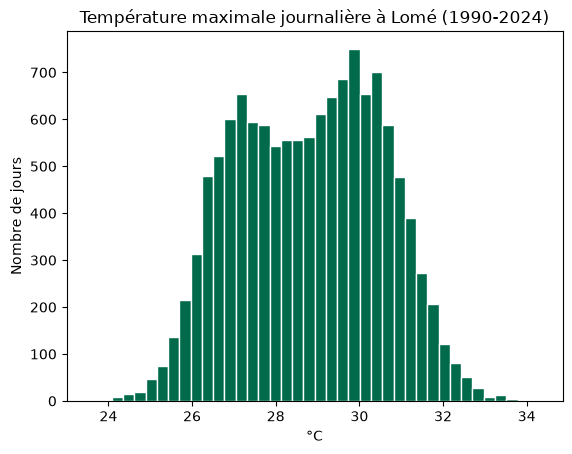

In [7]:
plt.hist(donnees["temperature_max"], bins=40, color="#006A4A", edgecolor="white")
plt.title("Température maximale journalière à Lomé (1990-2024)")
plt.xlabel("°C")
plt.ylabel("Nombre de jours")
plt.show()

## Étape 5 · Les saisons

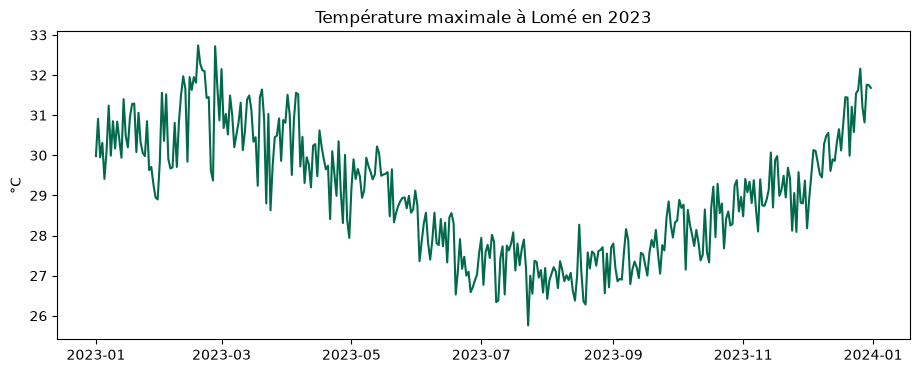

In [8]:
une_annee = donnees[donnees["date"].dt.year == 2023]

plt.figure(figsize=(11, 4))
plt.plot(une_annee["date"], une_annee["temperature_max"], color="#006A4A")
plt.title("Température maximale à Lomé en 2023")
plt.ylabel("°C")
plt.show()

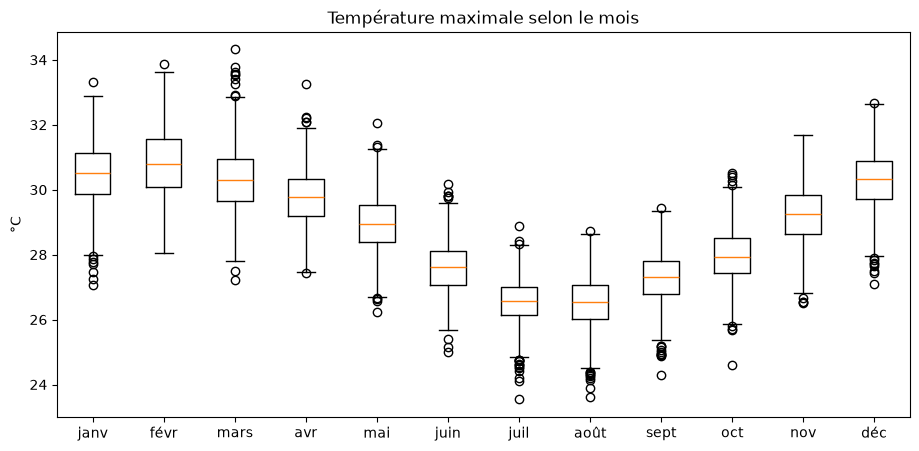

In [9]:
# Une boîte à moustaches par mois
mois = range(1, 13)
plt.figure(figsize=(11, 5))
plt.boxplot([donnees[donnees["date"].dt.month == m]["temperature_max"] for m in mois])
plt.xticks(range(1, 13), ["janv", "févr", "mars", "avr", "mai", "juin", "juil", "août", "sept", "oct", "nov", "déc"])
plt.title("Température maximale selon le mois")
plt.ylabel("°C")
plt.show()

**À regarder** : la saison chaude de janvier à avril, et la « petite saison froide » de juillet-août liée à la mousson. Les points isolés de chaque mois sont des journées inhabituelles pour la saison.

## Étape 6 · La tendance sur 35 ans

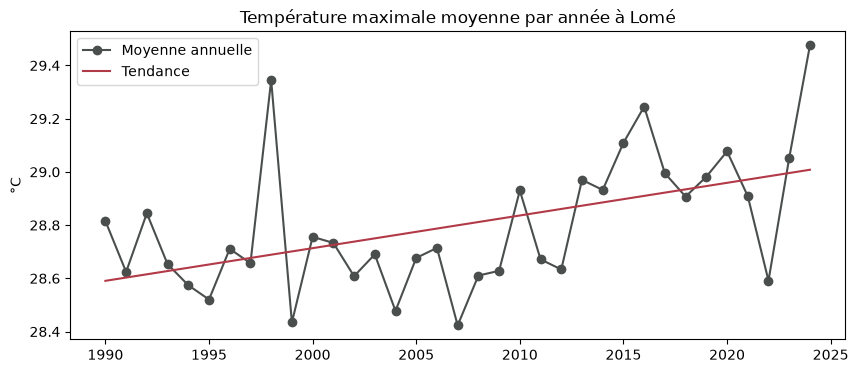

Réchauffement estimé : 0.12 °C par décennie


In [10]:
# Température maximale moyenne de chaque année
par_annee = donnees.groupby(donnees["date"].dt.year)["temperature_max"].mean()

# Droite de tendance : np.polyfit cherche la meilleure droite passant au milieu des points
pente, origine = np.polyfit(par_annee.index, par_annee.values, 1)

plt.figure(figsize=(10, 4))
plt.plot(par_annee.index, par_annee.values, marker="o", color="#4A4F4D", label="Moyenne annuelle")
plt.plot(par_annee.index, pente * par_annee.index + origine, color="#B23A48", label="Tendance")
plt.title("Température maximale moyenne par année à Lomé")
plt.ylabel("°C")
plt.legend()
plt.show()

print("Réchauffement estimé :", round(pente * 10, 2), "°C par décennie")

C'est une **régression linéaire simple** sur 35 points. Elle résume la tendance, mais elle repose sur des données estimées : un résultat à confirmer avec les stations de l'ANAM avant toute publication.

## Étape 7 · Les valeurs extrêmes : la pluie

**La règle des quartiles (ou règle de Tukey)**, la plus utilisée pour repérer des valeurs aberrantes :
- Q1 = la valeur sous laquelle se trouvent 25 % des observations ; Q3 = celle sous laquelle se trouvent 75 % ;
- l'écart interquartile vaut Q3 − Q1 ;
- une valeur est dite **aberrante** si elle est en dessous de Q1 − 1,5 × écart ou au-dessus de Q3 + 1,5 × écart.

Attention : *aberrant* veut dire *inhabituel*, pas forcément *faux*. Chaque valeur repérée se discute avec la connaissance du terrain.

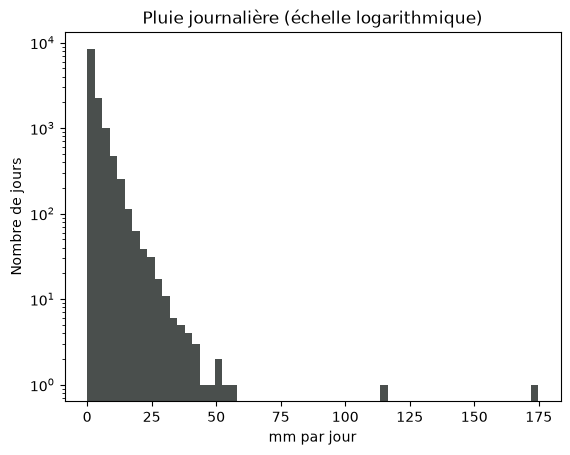

In [11]:
plt.hist(donnees["pluie"], bins=60, color="#4A4F4D")
plt.yscale("log")                       # échelle logarithmique : sinon les jours de forte pluie seraient invisibles
plt.title("Pluie journalière (échelle logarithmique)")
plt.xlabel("mm par jour")
plt.ylabel("Nombre de jours")
plt.show()

In [12]:
q1 = donnees["pluie"].quantile(0.25)
q3 = donnees["pluie"].quantile(0.75)
limite_haute = q3 + 1.5 * (q3 - q1)
print("Limite haute de la règle des quartiles :", round(limite_haute, 1), "mm")
print("Jours au-dessus :", (donnees["pluie"] > limite_haute).sum(), "sur", len(donnees))
print()
print("Les 5 journées les plus pluvieuses :")
donnees.nlargest(5, "pluie")[["date", "pluie", "temperature_max"]]

Limite haute de la règle des quartiles : 9.7 mm
Jours au-dessus : 831 sur 12784

Les 5 journées les plus pluvieuses :


,date,pluie,temperature_max
11112,2020-06-04,174.73,27.92
11093,2020-05-16,114.45,29.51
175,1990-06-25,56.38,27.18
12700,2024-10-09,53.42,27.54
4947,2003-07-19,50.86,25.66


**À discuter** : la règle des quartiles signale des centaines de jours, parce que la pluie est très « asymétrique » : beaucoup de jours secs ou presque, quelques jours très pluvieux. Ces fortes pluies sont **réelles** et importantes pour le climat. Ici, la règle des quartiles n'est pas adaptée : on garde toutes les valeurs.
Vérifiez à la source (presse, ANAM) si les journées les plus pluvieuses correspondent à des inondations connues.

## Étape 8 · Les valeurs inhabituelles : les sauts de température d'un jour à l'autre

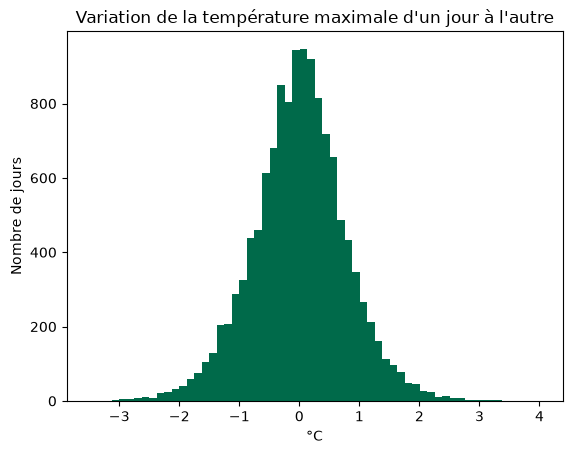

Jours où la température maximale change de plus de 3 °C : 14


,date,temperature_max,variation,pluie
833,1992-04-13,31.10,3.08,6.22
1522,1994-03-03,31.59,3.08,0.89
2163,1995-12-04,32.13,4.01,0.13
2467,1996-10-03,24.59,-3.50,5.99
4462,2002-03-21,32.22,3.05,1.37
4808,2003-03-02,33.42,3.76,0.04
5135,2004-01-23,31.99,3.21,1.68
5869,2006-01-26,29.22,-3.05,0.28
5872,2006-01-29,32.51,3.19,0.21
9570,2016-03-15,32.24,3.27,4.26


In [13]:
donnees["variation"] = donnees["temperature_max"].diff()      # différence avec la veille

plt.hist(donnees["variation"].dropna(), bins=60, color="#006A4A")
plt.title("Variation de la température maximale d'un jour à l'autre")
plt.xlabel("°C")
plt.ylabel("Nombre de jours")
plt.show()

gros_sauts = donnees[donnees["variation"].abs() > 3]
print("Jours où la température maximale change de plus de 3 °C :", len(gros_sauts))
gros_sauts[["date", "temperature_max", "variation", "pluie"]].head(10)

La plupart des jours, la température varie de moins d'un degré. Les gros sauts coïncident-ils avec de fortes pluies ? Comparez la colonne `pluie`.

## Étape 9 · Les liens entre variables

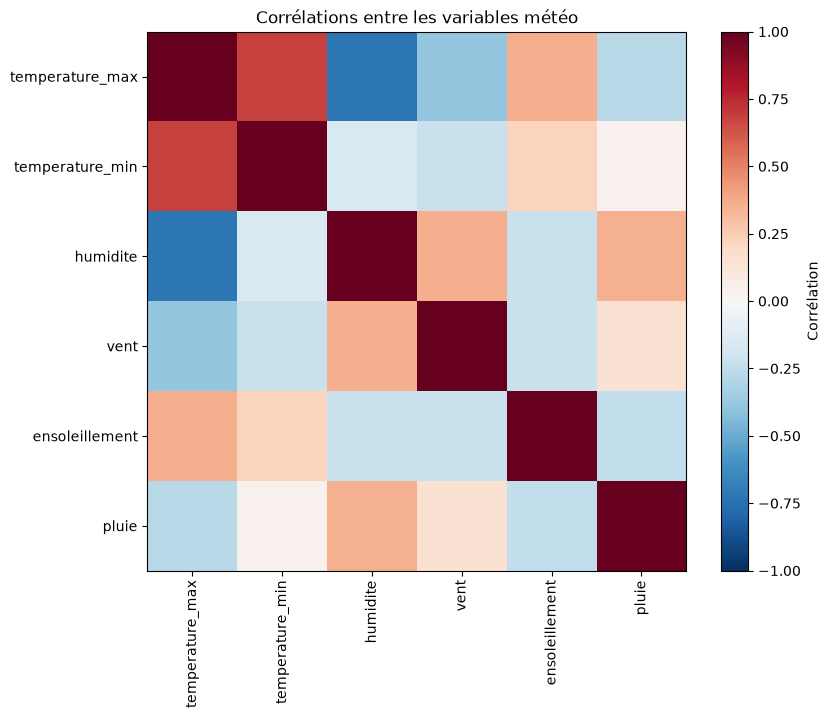

In [14]:
correlations = donnees[["temperature_max", "temperature_min", "humidite", "vent", "ensoleillement", "pluie"]].corr()      # corrélation entre chaque paire de colonnes (de -1 à 1)

plt.figure(figsize=(9, 7))
plt.imshow(correlations, cmap="RdBu_r", vmin=-1, vmax=1)    # rouge = varient ensemble, bleu = en sens contraire
plt.colorbar(label="Corrélation")
plt.xticks(range(len(correlations)), correlations.columns, rotation=90)
plt.yticks(range(len(correlations)), correlations.columns)
plt.title("Corrélations entre les variables météo")
plt.show()

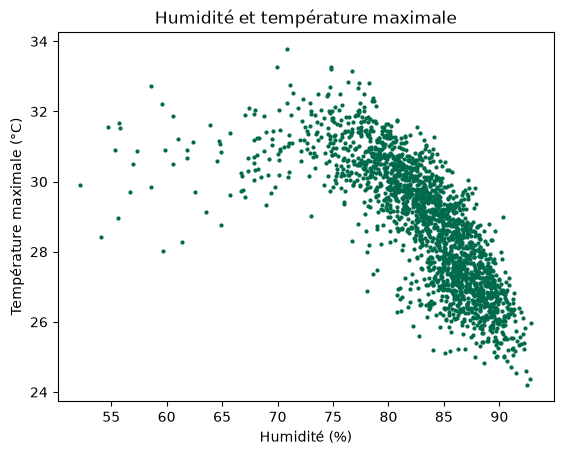

In [15]:
echantillon = donnees.sample(2000, random_state=1)        # 2 000 jours tirés au hasard, pour un graphique lisible
plt.scatter(echantillon["humidite"], echantillon["temperature_max"], s=4, color="#006A4A")
plt.xlabel("Humidité (%)")
plt.ylabel("Température maximale (°C)")
plt.title("Humidité et température maximale")
plt.show()

# Partie B · Construire les modèles

## Étape 10 · Préparer les données : la météo de la veille

Pour prévoir la température d'aujourd'hui, le modèle ne doit utiliser que ce que l'on connaît **déjà** : la météo d'hier. `shift(1)` décale chaque colonne d'un jour : sur la ligne d'aujourd'hui, on lit la valeur d'hier.

In [16]:
donnees["tmax_hier"] = donnees["temperature_max"].shift(1)
donnees["tmin_hier"] = donnees["temperature_min"].shift(1)
donnees["humidite_hier"] = donnees["humidite"].shift(1)
donnees["vent_hier"] = donnees["vent"].shift(1)
donnees["ensoleillement_hier"] = donnees["ensoleillement"].shift(1)
donnees["pluie_hier"] = donnees["pluie"].shift(1)
donnees["mois"] = donnees["date"].dt.month

donnees = donnees.dropna()      # le premier jour n'a pas de « veille »

colonnes = ["tmax_hier", "tmin_hier", "humidite_hier", "vent_hier", "ensoleillement_hier", "pluie_hier", "mois"]
cible = "temperature_max"
donnees[["date", "temperature_max", "tmax_hier", "humidite_hier", "pluie_hier"]].head()

,date,temperature_max,tmax_hier,humidite_hier,pluie_hier
1,1990-01-02,28.68,29.82,79.53,0.0
2,1990-01-03,29.87,28.68,85.41,0.0
3,1990-01-04,30.00,29.87,81.35,0.0
4,1990-01-05,29.51,30.00,79.54,0.0
5,1990-01-06,29.95,29.51,79.88,0.0


## Étape 11 · Séparer dans le temps

Avec des données qui se suivent, on ne mélange pas au hasard : on apprend sur le **passé** (1990-2018) et on teste sur les **années récentes** (2019-2024), comme dans une vraie prévision.

In [17]:
apprentissage = donnees[donnees["date"].dt.year <= 2018]
test = donnees[donnees["date"].dt.year >= 2019].copy()

print("Jours pour apprendre :", len(apprentissage), "(1990-2018)")
print("Jours pour tester :", len(test), "(2019-2024)")

Jours pour apprendre : 10591 (1990-2018)
Jours pour tester : 2192 (2019-2024)


## Étape 12 · La référence : « même température qu'hier »

C'est la prévision la plus naïve. Un modèle n'a d'intérêt que s'il fait mieux.

In [18]:
erreur_reference = mean_absolute_error(test[cible], test["tmax_hier"])
print("Erreur moyenne en prévoyant « comme hier » :", round(erreur_reference, 2), "°C")

Erreur moyenne en prévoyant « comme hier » : 0.62 °C


## Étape 13 · Premier modèle : la régression linéaire

In [19]:
lineaire = LinearRegression()
lineaire.fit(apprentissage[colonnes], apprentissage[cible])

test["prevision_lineaire"] = lineaire.predict(test[colonnes])
print("Erreur moyenne (régression linéaire) :", round(mean_absolute_error(test[cible], test["prevision_lineaire"]), 2), "°C")

# Ce que la régression a appris : le poids de chaque mesure de la veille
pd.Series(lineaire.coef_, index=colonnes).round(3)

Erreur moyenne (régression linéaire) : 0.56 °C


tmax_hier              0.548
tmin_hier              0.325
humidite_hier         -0.056
vent_hier             -0.190
ensoleillement_hier   -0.023
pluie_hier            -0.023
mois                  -0.020
dtype: float64

**Lire les poids** : un poids de 0,55 pour `tmax_hier` signifie qu'un degré de plus hier donne environ 0,55 degré de plus prévu aujourd'hui, toutes choses égales par ailleurs.

## Étape 14 · Modèle d'IA : la forêt aléatoire

In [20]:
foret = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
foret.fit(apprentissage[colonnes], apprentissage[cible])

test["prevision_foret"] = foret.predict(test[colonnes])
print("Erreur moyenne (forêt aléatoire) :", round(mean_absolute_error(test[cible], test["prevision_foret"]), 2), "°C")

Erreur moyenne (forêt aléatoire) : 0.54 °C


# Partie C · Analyser les résultats

## Étape 15 · Comparer les trois prévisions

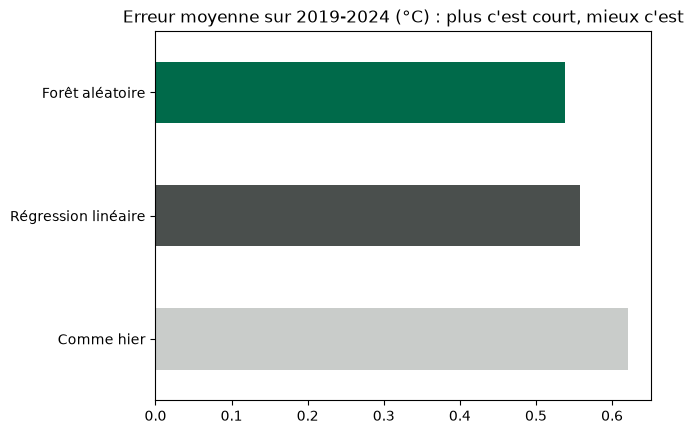

Comme hier             0.621
Régression linéaire    0.558
Forêt aléatoire        0.538
dtype: float64

In [21]:
resultats = pd.Series({
    "Comme hier": erreur_reference,
    "Régression linéaire": mean_absolute_error(test[cible], test["prevision_lineaire"]),
    "Forêt aléatoire": mean_absolute_error(test[cible], test["prevision_foret"])})

resultats.plot(kind="barh", color=["#C9CCCA", "#4A4F4D", "#006A4A"])
plt.title("Erreur moyenne sur 2019-2024 (°C) : plus c'est court, mieux c'est")
plt.show()
resultats.round(3)

## Étape 16 · Prévisions et réalité

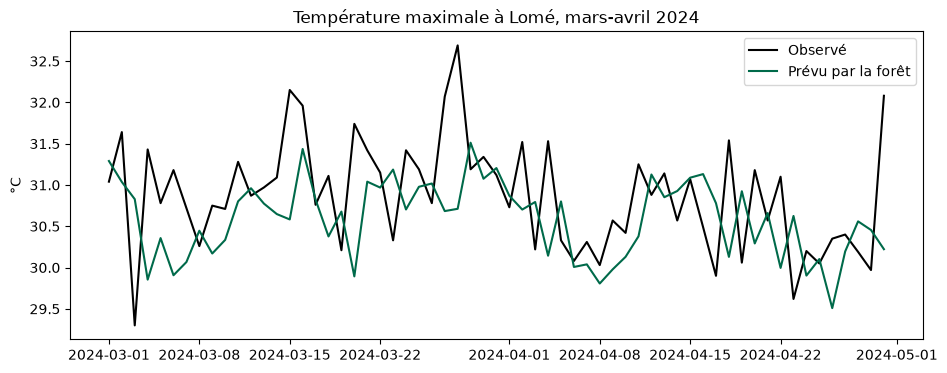

In [22]:
periode = test[(test["date"] >= "2024-03-01") & (test["date"] < "2024-05-01")]

plt.figure(figsize=(11, 4))
plt.plot(periode["date"], periode[cible], label="Observé", color="black")
plt.plot(periode["date"], periode["prevision_foret"], label="Prévu par la forêt", color="#006A4A")
plt.ylabel("°C")
plt.title("Température maximale à Lomé, mars-avril 2024")
plt.legend()
plt.show()

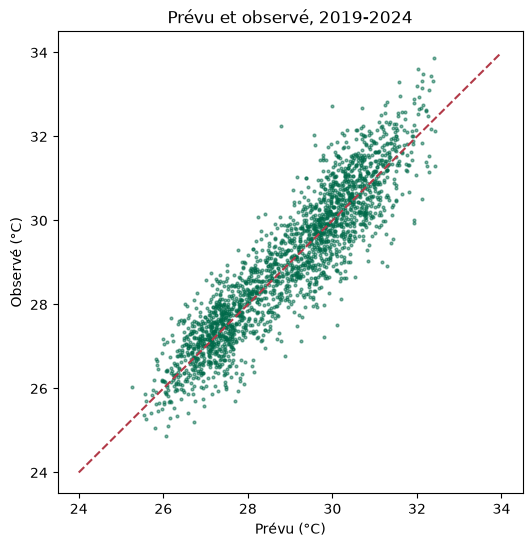

In [23]:
# Chaque point est un jour : la prévision (horizontal) contre la réalité (vertical). Une prévision parfaite serait sur la diagonale.
plt.figure(figsize=(6, 6))
plt.scatter(test["prevision_foret"], test[cible], s=4, alpha=0.5, color="#006A4A")
plt.plot([24, 34], [24, 34], color="#B23A48", linestyle="--")
plt.xlabel("Prévu (°C)")
plt.ylabel("Observé (°C)")
plt.title("Prévu et observé, 2019-2024")
plt.show()

**À regarder** : la forêt prévoit rarement les journées extrêmes. Ses prévisions restent « au milieu » : c'est typique d'un modèle qui fait des moyennes.

## Étape 17 · Les erreurs (résidus)

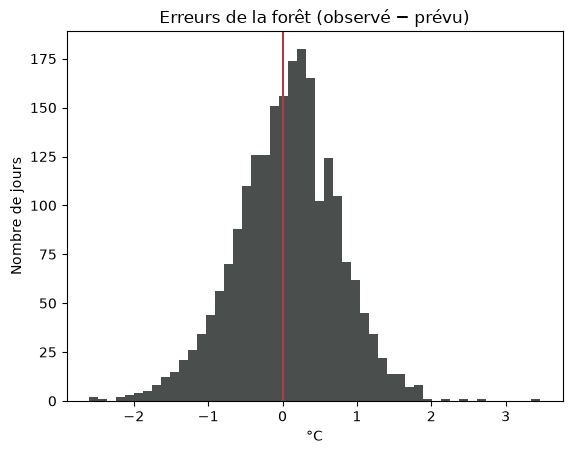

Jours prévus à moins de 0,5 °C près : 55.6 %
Jours ratés de plus de 2 °C : 12


In [24]:
test["erreur"] = test[cible] - test["prevision_foret"]      # positif : il a fait plus chaud que prévu

plt.hist(test["erreur"], bins=50, color="#4A4F4D")
plt.axvline(0, color="#B23A48")
plt.title("Erreurs de la forêt (observé − prévu)")
plt.xlabel("°C")
plt.ylabel("Nombre de jours")
plt.show()

print("Jours prévus à moins de 0,5 °C près :", round((test["erreur"].abs() < 0.5).mean() * 100, 1), "%")
print("Jours ratés de plus de 2 °C :", (test["erreur"].abs() > 2).sum())

## Étape 18 · Quelle saison est la plus difficile à prévoir ?

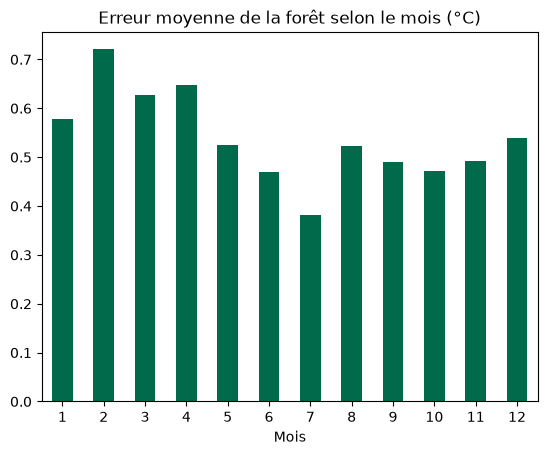

In [25]:
erreur_par_mois = test.groupby(test["date"].dt.month)["erreur"].apply(lambda e: e.abs().mean())

erreur_par_mois.plot(kind="bar", color="#006A4A", rot=0)
plt.title("Erreur moyenne de la forêt selon le mois (°C)")
plt.xlabel("Mois")
plt.show()

## Étape 19 · Les jours les plus ratés

In [26]:
test.reindex(test["erreur"].abs().sort_values(ascending=False).index).head(8)[
    ["date", "temperature_max", "prevision_foret", "erreur", "pluie", "pluie_hier"]].round({"prevision_foret": 2, "erreur": 2})

,date,temperature_max,prevision_foret,erreur,pluie,pluie_hier
11052,2020-04-05,32.24,28.78,3.46,1.41,13.00
12109,2023-02-26,32.72,29.99,2.73,1.76,1.56
11395,2021-03-14,27.51,30.11,-2.60,6.02,3.03
11404,2021-03-23,27.22,29.80,-2.58,16.98,36.07
11392,2021-03-11,32.04,29.55,2.49,1.68,2.07
11683,2021-12-27,28.92,31.29,-2.37,0.24,0.00
10620,2019-01-29,31.79,29.58,2.21,6.35,6.88
12761,2024-12-09,29.00,31.17,-2.17,0.01,0.01


**À discuter** : regardez la pluie du jour et de la veille. Une pluie change brutalement la température, dans un sens ou dans l'autre : après un jour pluvieux, le modèle prévoit un jour frais, alors que le ciel peut s'être dégagé. La météo de la veille ne suffit pas à anticiper ces changements.

## Étape 20 · Le résultat est-il stable d'une année à l'autre ?

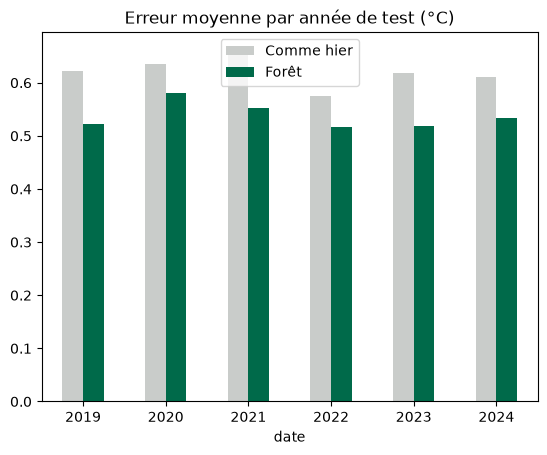

,Comme hier,Forêt
date,,
2019,0.62,0.52
2020,0.63,0.58
2021,0.66,0.55
2022,0.57,0.52
2023,0.62,0.52
2024,0.61,0.53


In [27]:
par_annee_test = test.groupby(test["date"].dt.year).apply(
    lambda jours: pd.Series({
        "Comme hier": mean_absolute_error(jours[cible], jours["tmax_hier"]),
        "Forêt": mean_absolute_error(jours[cible], jours["prevision_foret"])}))

par_annee_test.plot(kind="bar", color=["#C9CCCA", "#006A4A"], rot=0)
plt.title("Erreur moyenne par année de test (°C)")
plt.show()
par_annee_test.round(2)

## Étape 21 · Ce qui compte pour la forêt

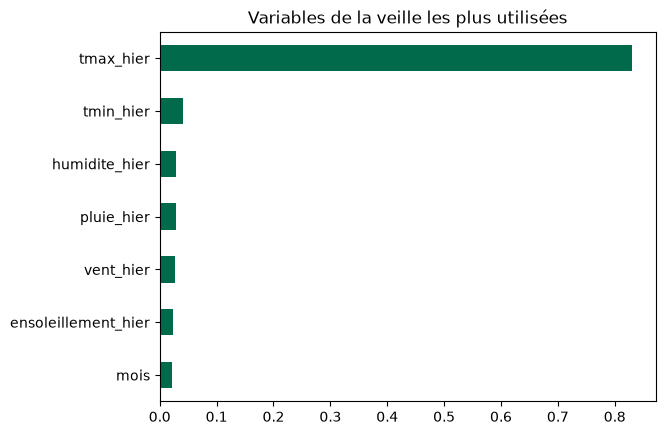

In [28]:
pd.Series(foret.feature_importances_, index=colonnes).sort_values().plot(kind="barh", color="#006A4A")
plt.title("Variables de la veille les plus utilisées")
plt.show()

# Partie D · Conclure

## Étape 22 · Limites

- Données estimées (satellite et réanalyse), pas mesurées par une station : à comparer avec les relevés de l'ANAM si vous y avez accès.
- On prévoit seulement le lendemain, avec les seules variables locales.
- Le modèle le plus complexe n'est pas forcément le meilleur : comparez toujours à « comme hier » et à la régression linéaire.